<a href="https://colab.research.google.com/github/rakeshma-72/LLM/blob/main/LLM_Tokenisation_exp1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

RAKESH M A
ENG23CS0157

In [22]:
!pip install -q transformers datasets sentencepiece accelerate

In [2]:
!pip install -q scikit-learn matplotlib

In [3]:
import torch

In [4]:
import transformers
print(transformers.__version__)

5.22.1


In [5]:
print("gpu available : ",torch.cuda.is_available())

gpu available :  True


In [6]:
if torch.cuda.is_available():
  print("gpu name : ", torch.cuda.get_device_name(0))

gpu name :  Tesla T4


In [8]:
from transformers import AutoTokenizer, AutoModel
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt

In [9]:
bert_tokenizer = AutoTokenizer.from_pretrained("bert-base-uncased")
gpt_tokenizer = AutoTokenizer.from_pretrained("gpt2")
print("pretained tokenizer loaded successfully..")

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

pretained tokenizer loaded successfully..


In [10]:
text = "Artifcial inteligence is transforming health care through deep learning"
print(text)

Artifcial inteligence is transforming health care through deep learning


In [12]:
bert_tokens = bert_tokenizer.tokenize(text)
print("bert tokens : ",bert_tokens)

bert tokens :  ['art', '##if', '##cial', 'intel', '##igen', '##ce', 'is', 'transforming', 'health', 'care', 'through', 'deep', 'learning']


In [13]:
bert_id = bert_tokenizer.convert_tokens_to_ids(bert_tokens)
print("token id of bert: ",bert_id)

token id of bert:  [2396, 10128, 13247, 13420, 29206, 3401, 2003, 17903, 2740, 2729, 2083, 2784, 4083]


In [14]:
gpt_tokens = gpt_tokenizer.tokenize(text)
print("bert tokens : ",gpt_tokens)

bert tokens :  ['Art', 'if', 'cial', 'Ġintel', 'ig', 'ence', 'Ġis', 'Ġtransforming', 'Ġhealth', 'Ġcare', 'Ġthrough', 'Ġdeep', 'Ġlearning']


In [15]:
gpt_id = gpt_tokenizer.convert_tokens_to_ids(gpt_tokens)
print("token id of gpt: ",gpt_id)

token id of gpt:  [8001, 361, 2413, 33649, 328, 594, 318, 25449, 1535, 1337, 832, 2769, 4673]


In [16]:
print("no of bert tokens :",len(bert_tokens))
print("no of gpt tokens : ",len(gpt_tokens))

no of bert tokens : 13
no of gpt tokens :  13


In [17]:
model = AutoModel.from_pretrained("bert-base-uncased")
print("model loaded successfully")

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


model loaded successfully


In [18]:
import torch
inputs = bert_tokenizer(text, return_tensors="pt")
outputs = model(**inputs)
embeddings = outputs.last_hidden_state
print("Embedding shape: ",embeddings.shape)

Embedding shape:  torch.Size([1, 15, 768])


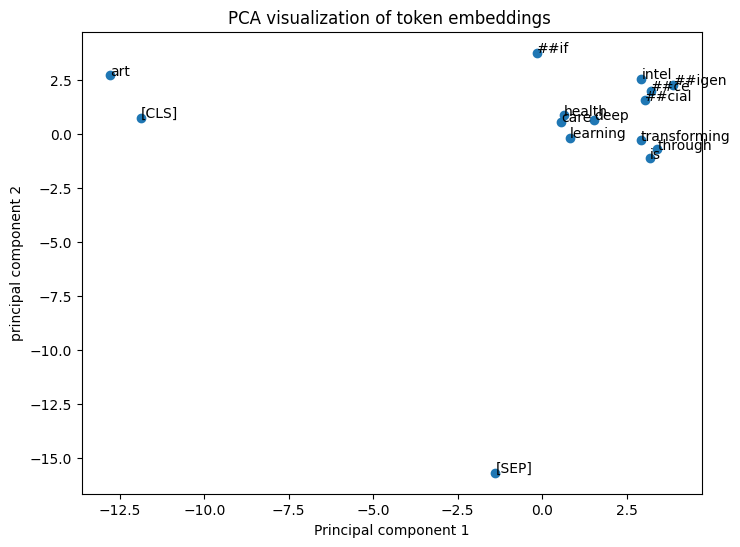

In [20]:
x = embeddings.squeeze().detach().numpy()
pca = PCA(n_components=2)
X_pca = pca.fit_transform(x)
tokens = bert_tokenizer.convert_ids_to_tokens(inputs["input_ids"][0])
plt.figure(figsize=(8,6))
plt.scatter(X_pca[:,0],X_pca[:,1])
for i,token in enumerate(tokens):
   plt.text(X_pca[i,0],X_pca[i,1],token)
plt.title("PCA visualization of token embeddings ")
plt.xlabel("Principal component 1")
plt.ylabel("principal component 2")
plt.show()

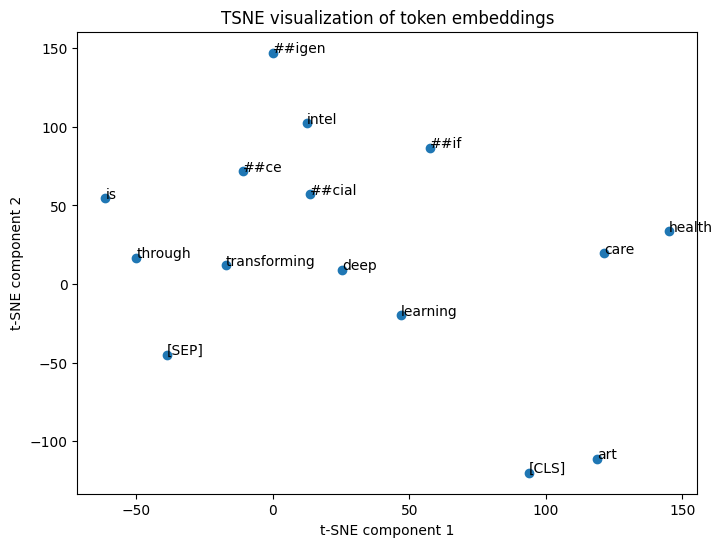

In [21]:
from sklearn.manifold import TSNE
tsne = TSNE(
    n_components = 2,
    perplexity = 5,
    random_state = 42
)
X_tsne = tsne.fit_transform(x)
plt.figure(figsize=(8,6))
plt.scatter(X_tsne[:,0],X_tsne[:,1])
for i,token in enumerate(tokens):
   plt.text(X_tsne[i,0],X_tsne[i,1],token)
plt.title("TSNE visualization of token embeddings")
plt.xlabel("t-SNE component 1")
plt.ylabel("t-SNE component 2")
plt.show()